# 07 · Fusion: one decision per order from the review AND the photo

**Goal:** turn three signals (review sentiment, issue tags, photo check) into one status per order,
**OK / REVIEW / URGENT**, with reasons a support agent can read, and show that combining them flags
problematic orders better than text or photo alone.

**Inputs:** the deployed ONNX models (`models/deploy/`, via `src/inference.py`), the text and image **test** splits.
**Outputs:** `results/metrics.json → fusion`, `results/fusion_simulated_test.csv`, figures, `demo_data/`.

All logic is in `src/fusion.py`.

> ⚠️ **The orders are simulated.** There is no public dataset of orders with both a review and a customer
> photo, so each order pairs a test review with a test photo from a *different* customer. Ground truth:
> an order is problematic if the photo's true label is bad **or** the review's true label is negative.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. How the decision is made

**Step 1, risk score:** `risk = w_text · P(negative) + w_img · P(bad photo) + w_tag · (any issue tag)`.
Without a photo the image weight is shared out over text and tags. `risk ≥ 0.70` → URGENT, `≥ 0.40` → REVIEW.

**Step 2, rules when review and photo can be compared** (a single weighted number would average away disagreement):

| review | photo | status | reason shown |
|---|---|---|---|
| negative | bad | URGENT | text and photo both show a problem |
| positive | bad | REVIEW | photo contradicts the positive review |
| claims damage/spoilage | clean | REVIEW | claim not visible in the photo: possible false claim |
| negative, no visible-damage claim | clean | REVIEW | service/product problem a photo can't show |
| neutral | bad | at least REVIEW | photo shows damage/rot |
| no photo | – | from the score | "decision based on the text only" |

A claim only counts as "not visible" if the photo model *could* see it: the package model sees box damage,
the produce model sees rot. "Stopped working" is not visible on a package photo, so it is not a false claim.

## 2. Run the experiment: simulated orders → deployed models → tuning → comparison

In [2]:
from src.fusion import run_fusion_experiment
exp = run_fusion_experiment()
test = exp["test"]
print(f"{len(exp['val'])} validation orders (for tuning), {len(test)} test orders (for results)")
pd.crosstab([test["category"], test["true_text"]], test["true_photo"], margins=True)

298 validation orders (for tuning), 298 test orders (for results)


true_photo             bad  good  All
category    true_text                
electronics negative    30    22   52
            neutral     15    22   37
            positive    15    45   60
grocery     negative    30    22   52
            neutral     15    22   37
            positive    15    45   60
All                    120   178  298

### Weight tuning (on the validation orders)
Grid search over all weights (step 0.05) and the REVIEW threshold. Because the rules already use the photo's
yes/no decision, hundreds of settings score almost the same; the single best one is extreme (text weight 1.0,
image weight 0). We therefore take the **most balanced** weights within 0.01 F1 of the best.

In [3]:
print("chosen:", exp["tuned"], "| validation F1", exp["val_f1"])
print("search:", exp["tuning_info"])

chosen: {'weights': {'text': 0.3, 'image': 0.4, 'tag': 0.3}, 'thresholds': {'review': 0.4, 'urgent': 0.7}} | validation F1 0.9053
search: {'best_val_f1': 0.915, 'single_best_settings': {'weights': {'text': 1.0, 'image': 0.0, 'tag': 0.0}, 'thresholds': {'review': 0.3, 'urgent': 0.7}}, 'n_within_tolerance': 780, 'tolerance': 0.01}


## 3. Results: text only vs photo only vs combined (test orders)

,precision,recall,f1,accuracy,flag_rate
text only (review negative),0.8557,0.5061,0.6360,0.6812,0.3255
text only (fusion without photo),0.8791,0.4878,0.6275,0.6812,0.3054
photo only (photo model says bad),0.8960,0.6829,0.7751,0.7819,0.4195
combined: weighted score only,0.9423,0.5976,0.7313,0.7584,0.3490
combined: score + rules (ours),0.8457,0.9024,0.8732,0.8557,0.5872


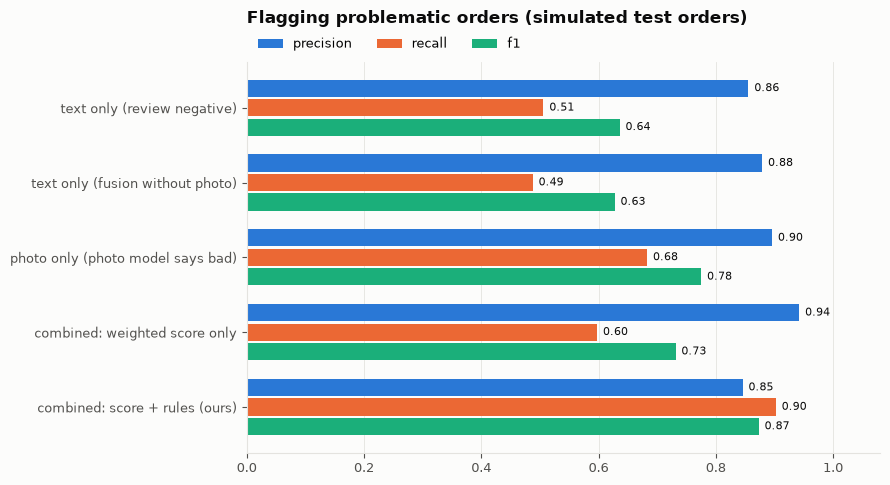

In [4]:
from src.fusion import plot_strategy_comparison
display(exp["comparison"])
plot_strategy_comparison(exp["comparison"]);

### How the statuses line up with the true situation

In [5]:
exp["status_table"]

status                OK  REVIEW  URGENT
true_text true_photo                    
negative  bad          0      16      44
          good        10      30       4
neutral   bad          4      20       6
          good        29      14       1
positive  bad          2      27       1
          good        78      12       0

## 4. Demo orders (for the video and the website)

12 hand-picked orders from the test splits that show every rule (`scripts/make_demo_data.py`).
Photos are the test photos the model is most confident about, so the live demo behaves as described.

,order_id,status,sentiment,tags,photo_p_bad,shows
0,DEMO-01,URGENT,negative,"damaged_packaging, defective_product",0.9998,negative review + damaged box -> URGENT
1,DEMO-02,URGENT,negative,"spoiled_food, refund_request",1.0000,negative review + rotten fruit -> URGENT
2,DEMO-03,REVIEW,positive,NaN,0.9998,positive review but damaged box -> REVIEW
3,DEMO-04,REVIEW,positive,NaN,1.0000,"'fresh, well packaged' but rotten photo -> REVIEW"
4,DEMO-05,REVIEW,negative,"damaged_packaging, defective_product",0.0015,"claims it came broken, box looks intact -> REVIEW (possible false claim)"
5,DEMO-06,REVIEW,negative,spoiled_food,0.0000,"claims stale/hard fruit, photo looks fresh -> REVIEW (possible false claim)"
6,DEMO-07,REVIEW,negative,defective_product,0.0079,"stopped working, box fine -> REVIEW (problem a photo can't show)"
7,DEMO-08,OK,positive,NaN,0.0088,"happy customer, intact box -> OK"
8,DEMO-09,OK,positive,NaN,0.0000,"happy customer, fresh fruit -> OK"
9,DEMO-10,URGENT,negative,refund_request,NaN,"angry review, no photo -> text-only decision"


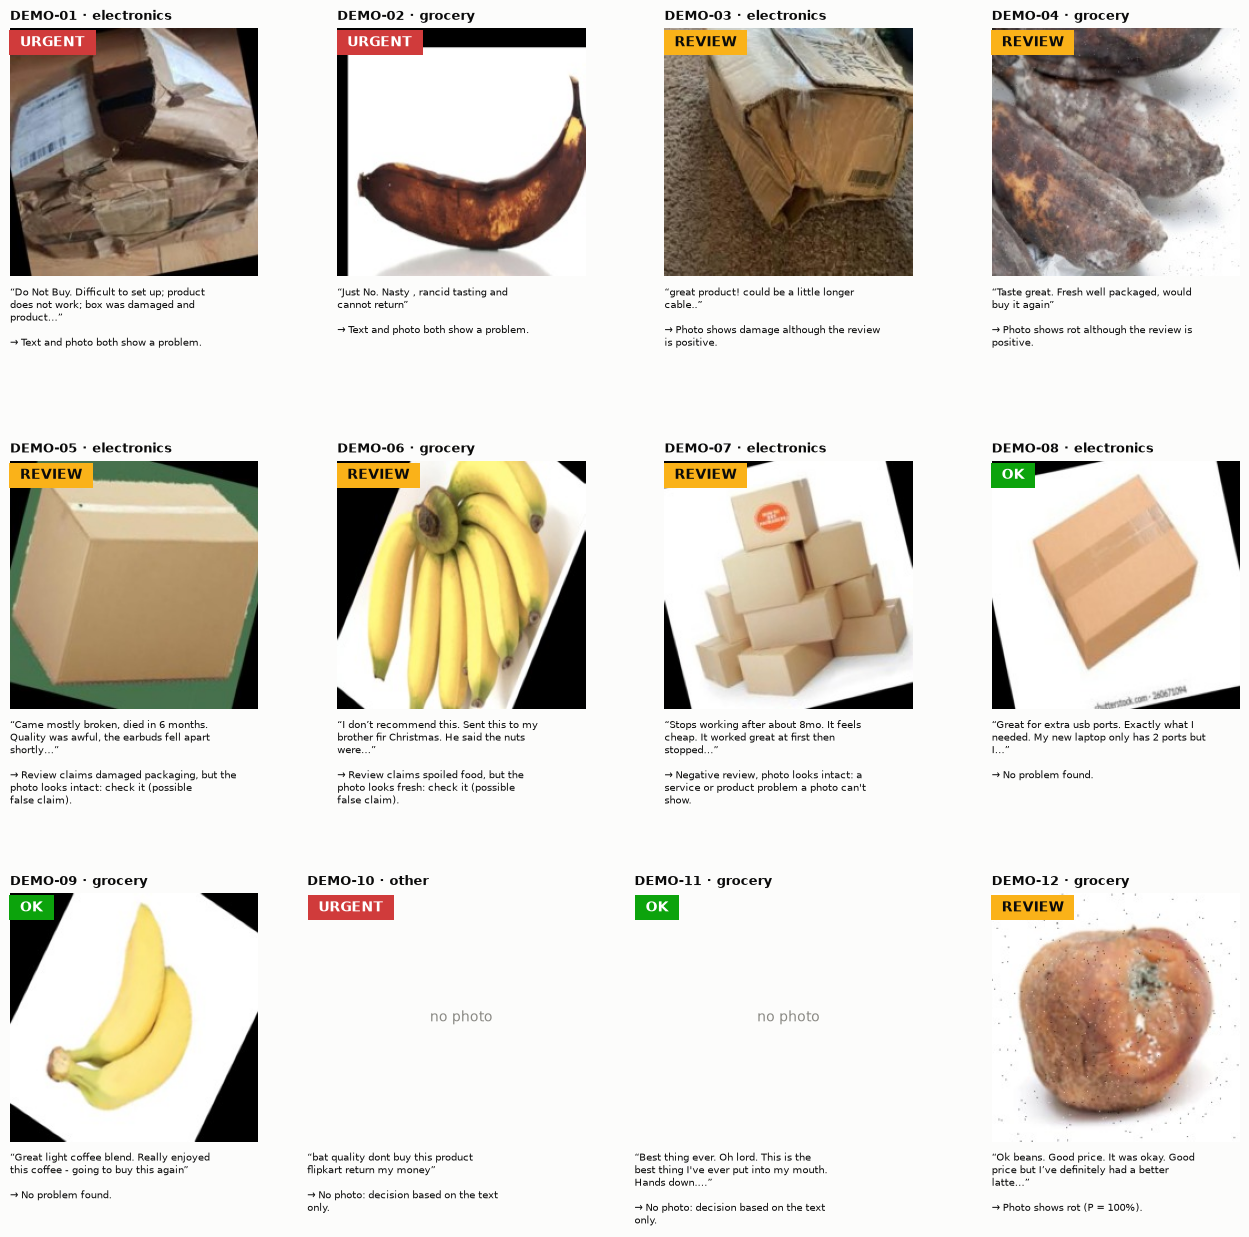

In [6]:
demo = pd.read_csv("../demo_data/expected.csv")
display(demo[["order_id", "status", "sentiment", "tags", "photo_p_bad", "shows"]])
from src.fusion import plot_demo_orders
plot_demo_orders();

## Key findings

- **Combining review and photo catches far more problematic orders.** On 298 simulated test orders, the fusion
  (score + rules) flags **90% of problematic orders** (recall 0.90, precision 0.85, F1 **0.87**), compared with
  51% for the review alone (F1 0.64) and 68% for the photo alone (F1 0.78).
- **The rules matter more than the weights.** A weighted score without rules reaches only F1 0.73, because it averages
  away the cases where review and photo *disagree*, and those are exactly the ones a person should check
  (happy review + damaged box, damage claim + intact box).
- **Weights barely matter** once the rules use the photo decision: 780 settings were within 0.01 F1 of the best.
  The chosen weights (text 0.30, photo 0.40, tags 0.30) keep every signal visible in the risk score.
- **Explainable by design:** every decision comes with reason codes, e.g. "Review claims damaged packaging, but the
  photo looks intact: check it (possible false claim)".
- **Trade-off:** fusion flags 59% of orders for a human (55% are truly problematic in this simulation). In a real shop
  the REVIEW threshold sets how many orders the support team must check.
- **Limitation:** pairs are simulated (review and photo from different customers), so real-world numbers will differ.